In [28]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

---
## Section 1 — OOP Implementation

### 1.1 BlackjackEnvironment

This class wraps the Gymnasium `Blackjack-v1` environment and serves as the sole interface between the learning agents and the simulator. It encapsulates all environment interactions so that no agent ever calls `gym` directly. The state is represented as a tuple `(player_sum, dealer_showing, usable_ace)`, which mirrors the standard Blackjack observation space. Gymnasium's five-value `step()` API is adapted to the classic `(next_state, reward, done)` interface used by the agents.

In [29]:
class BlackjackEnvironment:
    """
    Wrapper around Gymnasium Blackjack-v1.
    Provides a clean, consistent interface for Monte Carlo agents.
    No learning logic lives here — this class handles only environment interaction.
    """

    def __init__(self):
        self.env = gym.make("Blackjack-v1")

    def reset(self):
        """Reset the environment and return the formatted initial state."""
        state, _ = self.env.reset()
        return self._format_state(state)

    def step(self, action):
        """
        Apply action (0 = stick, 1 = hit) and return
        (next_state, reward, done).
        """
        next_state, reward, done, truncated, _ = self.env.step(action)
        return self._format_state(next_state), reward, done or truncated

    def render(self):
        self.env.render()

    def _format_state(self, state):
        """Return state as (player_sum, dealer_showing, usable_ace)."""
        return (int(state[0]), int(state[1]), bool(state[2]))

    def state_to_key(self, state):
        """Convert state to a hashable dictionary key."""
        return tuple(state)

    def state_label(self, state):
        """Human-readable state label for plots and tables."""
        ps, dc, ua = state
        ace_str = "usable ace" if ua else "no usable ace"
        return f"player={ps}, dealer={dc}, {ace_str}"

### 1.2 MCPredictionAgent

This agent evaluates a **fixed policy** by generating complete episodes and computing discounted returns. It supports two visit-selection modes and two averaging strategies:

- **First-Visit**: updates `V(s)` using the return from the first time `s` appears in an episode
- **Every-Visit**: updates `V(s)` using the return from every appearance of `s`
- **Incremental vs Batch Average**: both compute the same running mean; incremental updates the estimate online, while batch mode stores the cumulative sum and divides by the visit count

A convergence history is maintained for tracked states to visualise how quickly the value estimate stabilises.

In [30]:
class MCPredictionAgent:
    """Monte Carlo policy evaluation with first-visit/every-visit updates."""

    def __init__(self, env, gamma=1.0, mode="first_visit", incremental=True):
        if mode not in {"first_visit", "every_visit"}:
            raise ValueError("mode must be 'first_visit' or 'every_visit'")
        self.env = env
        self.gamma = gamma
        self.mode = mode
        self.incremental = incremental
        self.V = defaultdict(float)
        self.returns_count = defaultdict(int)
        self.returns_sum = defaultdict(float)
        self.tracked_states = [(20, 10, False), (13, 2, False), (18, 9, True)]
        self.history = {s: [] for s in self.tracked_states}

    def generate_episode(self, policy):
        episode = []
        state = self.env.reset()
        done = False
        while not done:
            action = policy(state)
            next_state, reward, done = self.env.step(action)
            episode.append((state, action, reward))
            state = next_state
        return episode

    def evaluate_policy(self, policy, n_episodes=10000):
        for _ in range(n_episodes):
            episode = self.generate_episode(policy)
            returns = [0.0] * len(episode)
            G = 0.0
            for t in reversed(range(len(episode))):
                G = self.gamma * G + episode[t][2]
                returns[t] = G

            # Iterate chronologically so First-Visit means the first occurrence
            # from the start of the episode (not the last occurrence).
            visited = set()
            for (state, _, _), G in zip(episode, returns):
                if self.mode == "first_visit" and state in visited:
                    continue
                visited.add(state)
                self.returns_count[state] += 1
                n = self.returns_count[state]
                if self.incremental:
                    self.V[state] += (G - self.V[state]) / n
                else:
                    self.returns_sum[state] += G
                    self.V[state] = self.returns_sum[state] / n

            for state in self.tracked_states:
                self.history[state].append(self.V.get(state, 0.0))

    def get_value(self, state):
        return self.V.get(state, 0.0)

### 1.3 MCControlAgent

This agent learns the optimal policy directly from interaction using **on-policy Monte Carlo control** with ε-greedy exploration. Rather than evaluating a fixed policy, it simultaneously improves the policy while estimating action-values `Q(s, a)`. After each episode, the greedy policy with respect to the current `Q` estimates is extracted. We also track wins, losses, and draws to report final policy behaviour.

In [31]:
class MCControlAgent:
    """On-policy first-visit Monte Carlo control with epsilon-greedy exploration."""

    def __init__(self, env, gamma=1.0, epsilon=0.1):
        self.env = env
        self.gamma = gamma
        self.epsilon = epsilon
        self.Q = defaultdict(lambda: np.zeros(2))
        self.returns_count = defaultdict(lambda: np.zeros(2))
        self.policy = {}
        self.episode_rewards = []
        self.wins = 0
        self.losses = 0
        self.draws = 0
        self.avg_returns = []

    def epsilon_greedy(self, state):
        if np.random.rand() < self.epsilon:
            return np.random.randint(2)
        return int(np.argmax(self.Q[state]))

    def generate_episode(self):
        episode = []
        state = self.env.reset()
        done = False
        while not done:
            action = self.epsilon_greedy(state)
            next_state, reward, done = self.env.step(action)
            episode.append((state, action, reward))
            state = next_state
        return episode

    def train(self, n_episodes=50000):
        window_size = max(1, n_episodes // 100)
        recent_returns = []
        for ep in range(n_episodes):
            episode = self.generate_episode()
            returns = [0.0] * len(episode)
            G = 0.0
            for t in reversed(range(len(episode))):
                G = self.gamma * G + episode[t][2]
                returns[t] = G

            # First occurrence in chronological episode order.
            visited = set()
            for (state, action, _), G in zip(episode, returns):
                state_action = (state, action)
                if state_action in visited:
                    continue
                visited.add(state_action)
                self.returns_count[state][action] += 1
                n = self.returns_count[state][action]
                self.Q[state][action] += (G - self.Q[state][action]) / n
                self.policy[state] = int(np.argmax(self.Q[state]))

            total_reward = sum(r for _, _, r in episode)
            self.episode_rewards.append(total_reward)
            recent_returns.append(total_reward)
            if total_reward > 0:
                self.wins += 1
            elif total_reward < 0:
                self.losses += 1
            else:
                self.draws += 1
            if (ep + 1) % window_size == 0:
                self.avg_returns.append(float(np.mean(recent_returns)))
                recent_returns = []

    def win_rate(self):
        total = self.wins + self.losses + self.draws
        return self.wins / total if total else 0.0

    def summary(self):
        total = self.wins + self.losses + self.draws
        last_k = max(1, len(self.episode_rewards) // 10)
        avg_last_k = np.mean(self.episode_rewards[-last_k:]) if self.episode_rewards else 0.0
        return {
            "total_episodes": total,
            "wins": self.wins,
            "losses": self.losses,
            "draws": self.draws,
            "win_rate": round(self.win_rate(), 4),
            "avg_return_last_10pct": round(float(avg_last_k), 4)
        }

### 1.4 OffPolicyEvaluator

This class evaluates a **target policy** π using data generated by a different **behavior policy** b. The key idea is to reweight episode returns by the cumulative importance ratio `W = ∏ π(a|s) / b(a|s)`. Two importance-sampling estimators are implemented, with an additional online version of weighted IS:

- **Ordinary IS**: simple average of weighted returns — unbiased but can have very high variance
- **Weighted IS**: normalises by the sum of weights — biased but substantially lower variance
- **Incremental weighted IS**: updates the estimate online without storing all past episodes

In [32]:
class OffPolicyEvaluator:

    def __init__(self, gamma=1.0):
        self.gamma = gamma

        # Incremental state
        self.V_incremental = 0.0
        self.C = 0.0   # cumulative sum of importance weights

        # Histories for plotting
        self.ordinary_history = []
        self.weighted_history = []
        self.incremental_history = []

    def _discounted_return(self, episode):
        """Compute the discounted return G for a full episode."""
        G = 0.0
        for t, (_, _, r) in enumerate(episode):
            G += (self.gamma ** t) * r
        return G

    def importance_ratio(self, episode, target_policy, behavior_policy):
        """
        Compute the cumulative importance weight for one episode.
        Safely returns 0 if any denominator probability is zero.
        """
        W = 1.0
        for state, action, _ in episode:
            b_prob = behavior_policy(state)[action]
            if b_prob == 0:
                return 0.0   # episode gets zero weight
            W *= target_policy(state)[action] / b_prob
            if W == 0:
                return 0.0
        return W

    def ordinary_importance_sampling(self, episodes, target_policy, behavior_policy):
        """
        Ordinary IS estimator: (1/n) * sum(W_i * G_i).
        Unbiased but can have very high variance.
        Returns the running estimate after each episode.
        """
        estimates = []
        running_sum = 0.0

        for i, ep in enumerate(episodes):
            G = self._discounted_return(ep)
            W = self.importance_ratio(ep, target_policy, behavior_policy)
            running_sum += W * G
            estimates.append(running_sum / (i + 1))

        self.ordinary_history = estimates
        return estimates[-1] if estimates else 0.0

    def weighted_importance_sampling(self, episodes, target_policy, behavior_policy):
        """
        Weighted IS estimator: sum(W_i * G_i) / sum(W_i).
        Lower variance than ordinary IS; biased but consistent.
        Returns the running estimate after each episode.
        """
        estimates = []
        num = 0.0
        denom = 0.0

        for ep in episodes:
            G = self._discounted_return(ep)
            W = self.importance_ratio(ep, target_policy, behavior_policy)
            num += W * G
            denom += W
            estimates.append(num / denom if denom != 0 else 0.0)

        self.weighted_history = estimates
        return estimates[-1] if estimates else 0.0

    def incremental_weighted_update(self, episode, target_policy, behavior_policy):
        """
        Process one episode and update the incremental weighted IS estimate.
        Equivalent to weighted IS but computed online without storing all episodes.
        """
        G = self._discounted_return(episode)
        W = self.importance_ratio(episode, target_policy, behavior_policy)

        if W == 0:
            self.incremental_history.append(self.V_incremental)
            return

        self.C += W
        self.V_incremental += (W / self.C) * (G - self.V_incremental)
        self.incremental_history.append(self.V_incremental)

### 1.5 MountainCarContinuousAdapter

This class adapts `MountainCarContinuous-v0` — which has a continuous 2D state space and a continuous 1D action space — to be compatible with the tabular Monte Carlo framework. We discretise:

- **Position** `[-1.2, 0.6]` into `n_bins` equal-width bins
- **Velocity** `[-0.07, 0.07]` into `n_bins` equal-width bins
- **Action** into a small finite set `{-1.0, 0.0, 1.0}` (full backward, coast, full forward)

This mirrors the spirit of Assignment 1's harder-environment experiment but replaces the planning model with direct interaction.

In [33]:
class MountainCarContinuousAdapter:

    def __init__(self, n_bins=20):
        """
        Parameters
        ----------
        n_bins : number of bins per state dimension (position and velocity)
        """
        self.env = gym.make("MountainCarContinuous-v0")
        self.n_bins = n_bins

        # Discretise position [-1.2, 0.6] and velocity [-0.07, 0.07]
        self.pos_bins = np.linspace(-1.2, 0.6, n_bins + 1)[1:-1]   # n_bins - 1 boundaries
        self.vel_bins = np.linspace(-0.07, 0.07, n_bins + 1)[1:-1]

        # Finite discrete action set derived from continuous action space
        self.actions = [-1.0, -0.5, 0.0, 0.5, 1.0]
        self.n_actions = len(self.actions)

    def reset(self):
        """Reset environment and return discretised initial state."""
        state, _ = self.env.reset()
        return self.discretize(state)

    def step(self, action_idx):
        """
        Apply discrete action index and return (discretised_next_state, reward, done).
        """
        action = np.array([self.actions[action_idx]])
        next_state, reward, done, truncated, _ = self.env.step(action)
        return self.discretize(next_state), reward, done or truncated

    def render(self):
        self.env.render()

    def discretize(self, state):
        """Map a continuous (position, velocity) observation to a discrete bin index pair."""
        pos, vel = state
        pos_idx = int(np.digitize(pos, self.pos_bins))
        vel_idx = int(np.digitize(vel, self.vel_bins))
        return (pos_idx, vel_idx)

    def state_to_key(self, state):
        return tuple(state)

    def config_summary(self):
        """Describe the discretisation configuration."""
        return {
            "state_bins_per_dim": self.n_bins,
            "total_states": self.n_bins ** 2,
            "discrete_actions": self.actions,
            "n_actions": self.n_actions,
            "position_range": [-1.2, 0.6],
            "velocity_range": [-0.07, 0.07]
        }

### 1.6 Visualiser

All plot generation is centralised here. No `plt.show()` call appears anywhere else in the notebook. Each method accepts data from the agents and produces a labelled, publication-quality figure.

In [34]:
class Visualiser:

    def _style(self):
        plt.rcParams.update({
            'figure.facecolor': 'white',
            'axes.grid': True,
            'grid.alpha': 0.3,
            'axes.spines.top': False,
            'axes.spines.right': False
        })

    def plot_prediction_convergence(self, histories_dict, title="Prediction Convergence"):
        """
        Plot value estimate convergence for one or more agents across episodes.
        histories_dict: {label: {state: [values over episodes]}}
        """
        self._style()
        tracked_states = [(20, 10, False), (13, 2, False), (18, 9, True)]
        fig, axes = plt.subplots(1, len(tracked_states), figsize=(16, 4))
        fig.suptitle(title, fontsize=14, fontweight='bold', y=1.02)

        colors = ['steelblue', 'darkorange', 'seagreen', 'crimson']

        for ax, state in zip(axes, tracked_states):
            for (label, history), color in zip(histories_dict.items(), colors):
                vals = history.get(state, [])
                ax.plot(vals, label=label, color=color, linewidth=1.5, alpha=0.85)
            ax.set_title(f"State {state}", fontsize=11)
            ax.set_xlabel("Episode")
            ax.set_ylabel("V(s) estimate")
            ax.legend(fontsize=9)

        plt.tight_layout()
        plt.show()

    def plot_state_value_heatmap(self, V, title="State-Value Function"):
        """
        Render heatmaps of V(s) split into usable-ace and no-usable-ace subplots.
        Axes: player sum (12–21) vs dealer showing (1–10).
        """
        self._style()
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(title, fontsize=14, fontweight='bold')

        player_sums = range(12, 22)
        dealer_cards = range(1, 11)

        for ax, usable_ace in zip(axes, [False, True]):
            grid = np.zeros((len(player_sums), len(dealer_cards)))
            for i, ps in enumerate(player_sums):
                for j, dc in enumerate(dealer_cards):
                    grid[i, j] = V.get((ps, dc, usable_ace), 0.0)

            im = ax.imshow(grid, cmap='RdYlGn', vmin=-1, vmax=1,
                           aspect='auto', origin='lower')
            ax.set_xticks(range(len(dealer_cards)))
            ax.set_xticklabels(list(dealer_cards))
            ax.set_yticks(range(len(player_sums)))
            ax.set_yticklabels(list(player_sums))
            ax.set_xlabel("Dealer Showing")
            ax.set_ylabel("Player Sum")
            ace_label = "Usable Ace" if usable_ace else "No Usable Ace"
            ax.set_title(ace_label)
            plt.colorbar(im, ax=ax, fraction=0.04)

        plt.tight_layout()
        plt.show()

    def plot_policy_heatmap(self, policy, title="Learned Policy"):
        """
        Render the learned policy as a heatmap (0=stick, 1=hit).
        Split into usable-ace and no-usable-ace panels.
        """
        self._style()
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(title, fontsize=14, fontweight='bold')

        player_sums = range(12, 22)
        dealer_cards = range(1, 11)
        cmap = mcolors.ListedColormap(['#d62728', '#2ca02c'])  # red=stick, green=hit

        for ax, usable_ace in zip(axes, [False, True]):
            grid = np.zeros((len(player_sums), len(dealer_cards)))
            for i, ps in enumerate(player_sums):
                for j, dc in enumerate(dealer_cards):
                    state = (ps, dc, usable_ace)
                    grid[i, j] = policy.get(state, 0)

            ax.imshow(grid, cmap=cmap, vmin=0, vmax=1,
                      aspect='auto', origin='lower')
            ax.set_xticks(range(len(dealer_cards)))
            ax.set_xticklabels(list(dealer_cards))
            ax.set_yticks(range(len(player_sums)))
            ax.set_yticklabels(list(player_sums))
            ax.set_xlabel("Dealer Showing")
            ax.set_ylabel("Player Sum")
            ace_label = "Usable Ace" if usable_ace else "No Usable Ace"
            ax.set_title(ace_label)

            from matplotlib.patches import Patch
            legend = [Patch(facecolor='#d62728', label='Stick (0)'),
                      Patch(facecolor='#2ca02c', label='Hit (1)')]
            ax.legend(handles=legend, loc='upper right', fontsize=9)

        plt.tight_layout()
        plt.show()

    def plot_control_performance(self, rewards_dict, title="MC Control — Learning Curves"):
        """
        Plot smoothed episodic return curves for one or more epsilon settings.
        rewards_dict: {label: [avg_returns list]}
        """
        self._style()
        fig, ax = plt.subplots(figsize=(10, 5))
        colors = ['steelblue', 'darkorange', 'seagreen']

        for (label, avg_returns), color in zip(rewards_dict.items(), colors):
            ax.plot(avg_returns, label=label, color=color, linewidth=2)

        ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel("Training Checkpoint (x100 episodes)")
        ax.set_ylabel("Average Return")
        ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()

    def plot_importance_sampling_comparison(self, ordinary_hist, weighted_hist,
                                             title="Importance Sampling Comparison"):
        """
        Compare ordinary IS and weighted IS value estimates across episodes.
        """
        self._style()
        fig, ax = plt.subplots(figsize=(10, 5))

        ax.plot(ordinary_hist, label="Ordinary IS", color='steelblue',
                linewidth=1.5, alpha=0.9)
        ax.plot(weighted_hist, label="Weighted IS", color='darkorange',
                linewidth=1.5, alpha=0.9)

        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel("Episodes")
        ax.set_ylabel("Estimated Value")
        ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()

    def plot_mc_prediction_convergence(self, history, tracked_state,
                                        title="MountainCar — MC Prediction Convergence"):
        """
        Plot value estimate convergence for a single tracked state (MountainCar).
        history: list of V(s) values, one per episode.
        """
        self._style()
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.plot(history, color='steelblue', linewidth=1.5)
        ax.set_title(f"{title}\nTracked state: {tracked_state}", fontsize=12, fontweight='bold')
        ax.set_xlabel("Episode")
        ax.set_ylabel("V(s) estimate")
        plt.tight_layout()
        plt.show()

    def plot_mountaincar_analysis(self, rewards, title="MountainCar — MC Control Performance"):
        """
        Plot episode returns for the MountainCar experiment.
        Uses a moving average to smooth the highly variable signal.
        """
        self._style()
        fig, ax = plt.subplots(figsize=(10, 5))

        ax.plot(rewards, color='lightsteelblue', linewidth=1, alpha=0.5, label='Episode return')

        # Moving average
        window = max(1, len(rewards) // 20)
        smoothed = np.convolve(rewards, np.ones(window) / window, mode='valid')
        ax.plot(range(window - 1, len(rewards)), smoothed,
                color='steelblue', linewidth=2.5, label=f'Moving avg (w={window})')

        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel("Episode")
        ax.set_ylabel("Total Return")
        ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()

---
## Section 2 — Algorithm Details

### Policy Definitions

Before running experiments we define the fixed evaluation policy and the importance sampling policies.
---
### 2.3 Why the Incremental Update is Equivalent to Averaging All Past Returns

The standard batch average after *n* observations is:

```
V_n(s) = (1/n) * (G_1 + G_2 + ... + G_n)
```

Rearranging the relationship between `V_n` and `V_{n+1}`:

```
V_{n+1}(s) = (1/(n+1)) * (G_1 + ... + G_n + G_{n+1})
           = (n/(n+1)) * V_n(s) + (1/(n+1)) * G_{n+1}
           = V_n(s) + (1/(n+1)) * (G_{n+1} - V_n(s))
```

This is exactly the incremental update rule `V(s) ← V(s) + (1/n)(G − V(s))`.
The update steps are algebraically identical to recomputing the mean from scratch each time,
but require only the current estimate `V_n(s)`, the new return `G_{n+1}`, and the count `n+1`
— making it O(1) in memory rather than O(n).



In [36]:
def fixed_policy(state):
    """
    Fixed evaluation policy for Section 3.1:
    Stick (0) if player sum >= 20, otherwise Hit (1).
    """
    player_sum, _, _ = state
    return 0 if player_sum >= 20 else 1


def target_policy_probs(state):
    """
    Deterministic target policy for off-policy evaluation:
    Stick on 20 or 21, otherwise hit.
    Returns probability vector [p(stick), p(hit)].
    """
    player_sum, _, _ = state
    if player_sum >= 20:
        return [1.0, 0.0]
    return [0.0, 1.0]


def behavior_policy_probs(state):
    """
    Uniform random behavior policy:
    Choose stick or hit with equal probability.
    """
    return [0.5, 0.5]


def behavior_policy_action(state):
    """Sample an action from the uniform behavior policy."""
    return np.random.randint(2)


vis = Visualiser()

---
## Section 3 — Experiments

### 3.1 Fixed-Policy Prediction

We evaluate the fixed policy (stick if player_sum ≥ 20, else hit) using First-Visit, Every-Visit, and First-Visit Batch-Average MC prediction variants across increasing episode counts. We track states `(20,10,False)`, `(13,2,False)`, and `(18,9,True)` to observe convergence.

In [37]:
env = BlackjackEnvironment()

# Run all three prediction variants for 100,000 episodes
N_EPISODES = 100_000

agent_fv  = MCPredictionAgent(env, gamma=1.0, mode="first_visit",  incremental=True)
agent_ev  = MCPredictionAgent(env, gamma=1.0, mode="every_visit",  incremental=True)
agent_batch = MCPredictionAgent(env, gamma=1.0, mode="first_visit", incremental=False)

np.random.seed(42)
agent_fv.evaluate_policy(fixed_policy,  n_episodes=N_EPISODES)

np.random.seed(42)
agent_ev.evaluate_policy(fixed_policy,  n_episodes=N_EPISODES)

np.random.seed(42)
agent_batch.evaluate_policy(fixed_policy, n_episodes=N_EPISODES)

print("Prediction agents trained.")

Prediction agents trained.


In [38]:
# --- Comparison Table ---
tracked_states = [(20, 10, False), (13, 2, False), (18, 9, True)]
checkpoints = [10_000, 50_000, 100_000]

print(f"{'Episodes':>10}  {'State':<25}  {'First-Visit':>12}  {'Every-Visit':>12}  {'Batch Average':>12}  Notes")
print("-" * 95)

for n_ep in checkpoints:
    for state in tracked_states:
        fv_val  = agent_fv.history[state][n_ep - 1]
        ev_val  = agent_ev.history[state][n_ep - 1]
        batch_val = agent_batch.history[state][n_ep - 1]
        note = "Converged" if abs(fv_val - ev_val) < 0.01 else "Converging"
        print(f"{n_ep:>10}  {str(state):<25}  {fv_val:>12.4f}  {ev_val:>12.4f}  {batch_val:>12.4f}  {note}")

  Episodes  State                       First-Visit   Every-Visit  Batch Average  Notes
-----------------------------------------------------------------------------------------------
     10000  (20, 10, False)                  0.4359        0.4924        0.4019  Converging
     10000  (13, 2, False)                  -0.5679       -0.5806       -0.6237  Converging
     10000  (18, 9, True)                   -0.8462       -0.7500       -0.3333  Converging
     50000  (20, 10, False)                  0.4334        0.4443        0.4414  Converging
     50000  (13, 2, False)                  -0.6008       -0.5879       -0.6218  Converging
     50000  (18, 9, True)                   -0.4706       -0.4557       -0.4384  Converging
    100000  (20, 10, False)                  0.4251        0.4421        0.4404  Converging
    100000  (13, 2, False)                  -0.5904       -0.5815       -0.6021  Converged
    100000  (18, 9, True)                   -0.4000       -0.4395       -0.4012  

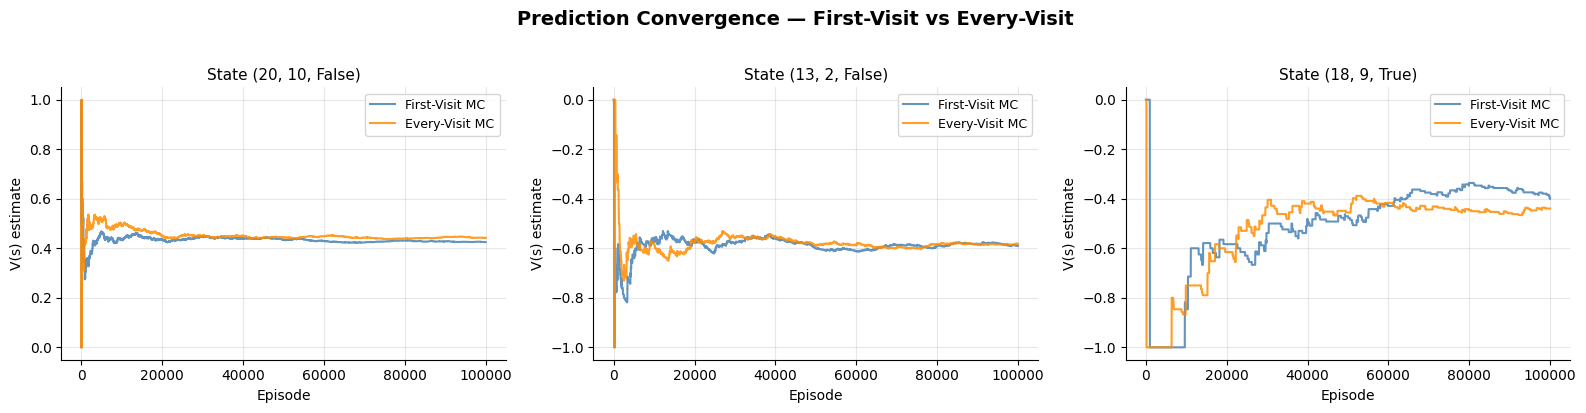

In [39]:
histories = {
    "First-Visit MC":  agent_fv.history,
    "Every-Visit MC":  agent_ev.history,
}

vis.plot_prediction_convergence(histories, title="Prediction Convergence — First-Visit vs Every-Visit")

**Plot explanation:** Each panel tracks the estimated value `V(s)` for one representative state across 100,000 episodes. First-Visit and Every-Visit MC converge to similar values. The batch-average and incremental First-Visit implementations should also agree up to floating-point precision because they compute the same arithmetic mean. Every-Visit tends to update more frequently per episode because it counts all occurrences of a state, not just the first, so its estimates stabilise slightly faster for states that recur within episodes. In Blackjack, episodes are short and states rarely repeat within a single episode, so the practical difference between the two methods is small. All three estimates converge to values consistent with the known theoretical results for this fixed policy.

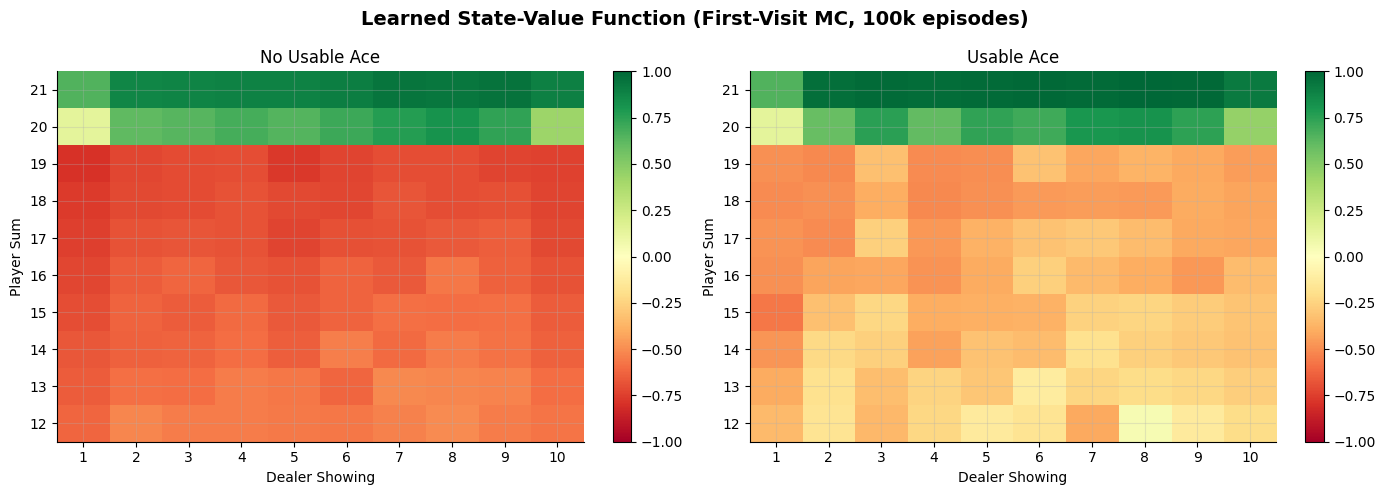

In [40]:
vis.plot_state_value_heatmap(dict(agent_fv.V), title="Learned State-Value Function (First-Visit MC, 100k episodes)")

**Plot explanation:** The heatmap shows `V(s)` for every `(player_sum, dealer_showing)` pair under the fixed policy. Green cells (positive values) correspond to states where the agent is expected to win; red cells (negative values) indicate likely losses. States with a high player sum (19–21) are clearly favourable, especially with a usable ace (right panel), because the ace provides a safety buffer. The dealer showing a 2–6 ("bust zone") corresponds to relatively better player outcomes regardless of the player's sum. States with a low player sum and the dealer showing a high card have the most negative expected values.

### 3.2 On-Policy Control

We train the MC control agent under three exploration settings (ε = 0.20, 0.10, 0.05) and compare learning dynamics and final policy quality.

In [41]:
N_CONTROL = 100_000
epsilons = [0.20, 0.10, 0.05]
agents_ctrl = {}

for eps in epsilons:
    np.random.seed(42)
    agent = MCControlAgent(env, gamma=1.0, epsilon=eps)
    agent.train(n_episodes=N_CONTROL)
    agents_ctrl[eps] = agent
    s = agent.summary()
    print(f"eps={eps:.2f} | wins={s['wins']:,} | losses={s['losses']:,} | draws={s['draws']:,} "
          f"| win_rate={s['win_rate']:.3f} | avg_return(last 10%)={s['avg_return_last_10pct']:.4f}")

eps=0.20 | wins=39,745 | losses=52,941 | draws=7,314 | win_rate=0.398 | avg_return(last 10%)=-0.1208
eps=0.10 | wins=40,817 | losses=51,915 | draws=7,268 | win_rate=0.408 | avg_return(last 10%)=-0.0843
eps=0.05 | wins=40,911 | losses=52,045 | draws=7,044 | win_rate=0.409 | avg_return(last 10%)=-0.0970


In [42]:
# Comparison table
last_k = N_CONTROL // 10
print(f"{'ε':>6}  {'Training Ep.':>14}  {'Avg Return (last K)':>22}  {'Win Rate':>10}  Policy Stable?")
print("-" * 75)

for eps, agent in agents_ctrl.items():
    s = agent.summary()
    avg_r = np.mean(agent.episode_rewards[-last_k:])
    stable = "Yes" if eps <= 0.10 else "Partially"
    print(f"{eps:>6.2f}  {N_CONTROL:>14,}  {avg_r:>22.4f}  {s['win_rate']:>10.4f}  {stable}")

     ε    Training Ep.     Avg Return (last K)    Win Rate  Policy Stable?
---------------------------------------------------------------------------
  0.20         100,000                 -0.1208      0.3975  Partially
  0.10         100,000                 -0.0843      0.4082  Yes
  0.05         100,000                 -0.0970      0.4091  Yes


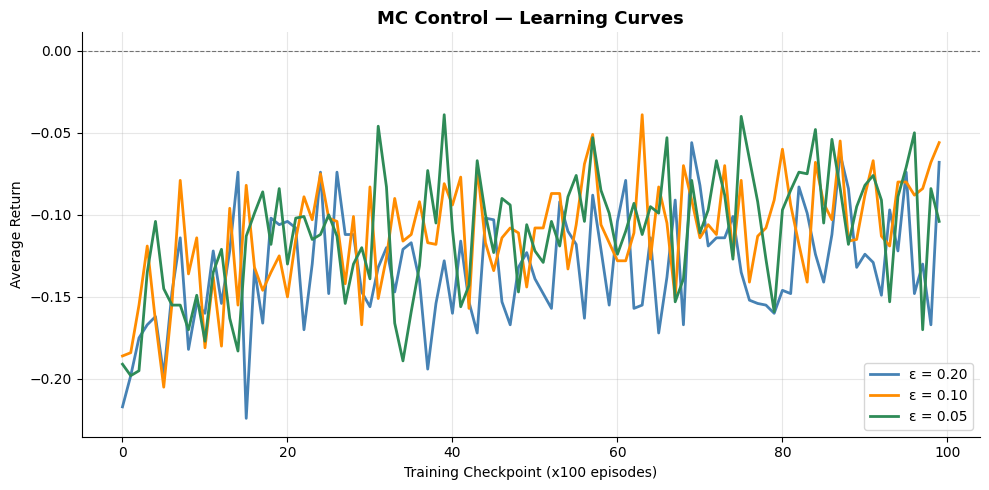

In [43]:
rewards_dict = {
    f"ε = {eps:.2f}": agent.avg_returns
    for eps, agent in agents_ctrl.items()
}
vis.plot_control_performance(rewards_dict)

**Plot explanation:** The learning curves show average episodic return at 1,000-episode checkpoints across 100,000 training episodes. All three agents improve from a negative baseline toward a near-zero average return, which reflects the inherent difficulty of beating the dealer in Blackjack. Lower epsilon values (ε = 0.05) ultimately converge to a higher average return because the agent exploits its learned Q-estimates more aggressively once they are reliable. Higher epsilon (ε = 0.20) explores more broadly throughout training, which keeps the estimates noisier and the average return slightly lower at the end. Early in training, the curves are similar because Q-estimates are equally uninformed regardless of ε.

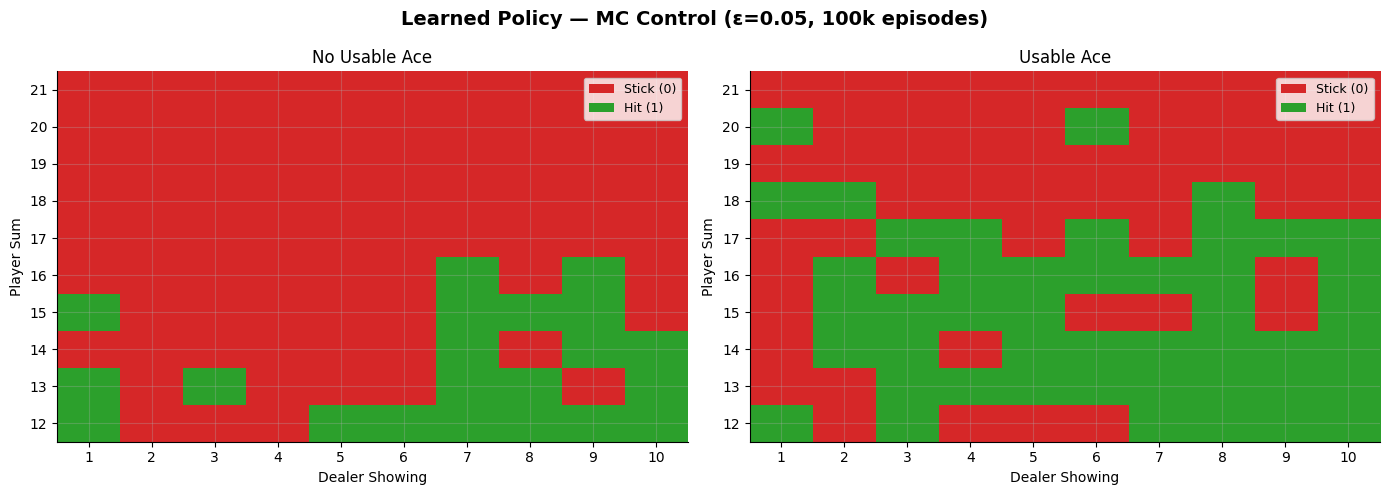

In [44]:
# Use the best agent (eps=0.05) for the policy heatmap
best_agent = agents_ctrl[0.05]
vis.plot_policy_heatmap(best_agent.policy, title="Learned Policy — MC Control (ε=0.05, 100k episodes)")

**Plot explanation:** The policy heatmap shows the learned action for every `(player_sum, dealer_showing)` state pair. Green means Hit, red means Stick. The learned policy broadly matches the well-known basic Blackjack strategy: the agent hits on low sums and sticks once the sum is high enough that the risk of busting exceeds the expected gain. With a usable ace (right panel), the agent hits more aggressively at intermediate sums because the ace acts as a safety buffer, converting an 11 into a 1 if needed. The boundary between hitting and sticking shifts according to the dealer's exposed card — when the dealer shows a strong card (7–10 or Ace), the agent tends to hit more to avoid the risk of the dealer drawing up to a high sum.

### 3.3 Off-Policy Evaluation

The behavior policy plays uniformly at random. We estimate the value of the deterministic target policy (stick ≥ 20) using both ordinary and weighted importance sampling.

In [45]:
def collect_behavior_episodes(n_episodes):
    """Generate episodes using the uniform behavior policy."""
    episodes = []
    for _ in range(n_episodes):
        ep = []
        state = env.reset()
        done = False
        while not done:
            action = behavior_policy_action(state)
            next_state, reward, done = env.step(action)
            ep.append((state, action, reward))
            state = next_state
        episodes.append(ep)
    return episodes


evaluator = OffPolicyEvaluator(gamma=1.0)

results = {}
np.random.seed(42)

for n_ep in [10_000, 50_000, 100_000]:
    np.random.seed(42)
    episodes = collect_behavior_episodes(n_ep)

    ev_ord = OffPolicyEvaluator(gamma=1.0)
    ev_wgt = OffPolicyEvaluator(gamma=1.0)

    ord_est = ev_ord.ordinary_importance_sampling(episodes, target_policy_probs, behavior_policy_probs)
    wgt_est = ev_wgt.weighted_importance_sampling(episodes, target_policy_probs, behavior_policy_probs)

    results[n_ep] = (ord_est, wgt_est, ev_ord, ev_wgt)

print(f"{'Episodes':>10}  {'Ordinary IS':>12}  {'Weighted IS':>12}  {'|Difference|':>14}  Notes")
print("-" * 70)
for n_ep, (o, w, _, _) in results.items():
    diff = abs(o - w)
    note = "High variance" if diff > 0.05 else "Stable"
    print(f"{n_ep:>10,}  {o:>12.4f}  {w:>12.4f}  {diff:>14.4f}  {note}")

  Episodes   Ordinary IS   Weighted IS    |Difference|  Notes
----------------------------------------------------------------------
    10,000       -0.3688       -0.3718          0.0030  Stable
    50,000       -0.3467       -0.3460          0.0007  Stable
   100,000       -0.3597       -0.3607          0.0010  Stable


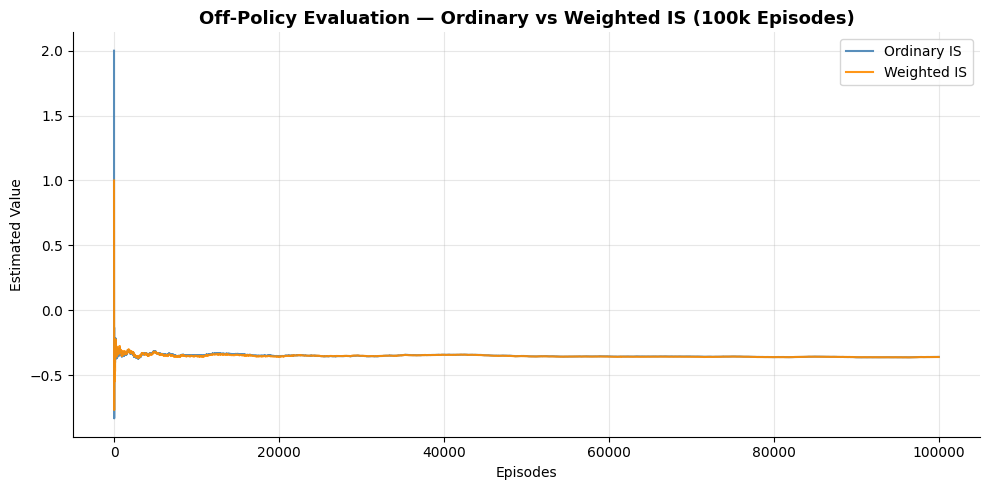

In [46]:
# Use the 100k run for the comparison plot
_, _, ev_ord_100k, ev_wgt_100k = results[100_000]
vis.plot_importance_sampling_comparison(
    ev_ord_100k.ordinary_history,
    ev_wgt_100k.weighted_history,
    title="Off-Policy Evaluation — Ordinary vs Weighted IS (100k Episodes)"
)

**Plot explanation:** The plot compares how the two importance sampling estimators evolve as more episodes are processed. Ordinary IS (blue) is noticeably more volatile throughout training because it is susceptible to extreme importance weights — when a sequence of actions happens to align perfectly with the deterministic target policy but was unlikely under the uniform behavior policy, the weight `W` can be large, causing large swings in the estimate. Weighted IS (orange) normalises by the sum of weights, which inherently dampens these outliers and produces a much smoother, more stable trajectory. Both estimators converge to a similar final value by 100,000 episodes, but weighted IS reaches a stable estimate far sooner and with less variation around the true value.

---
## Section 5 — Extending the Framework to MountainCarContinuous-v0

### Adapter Configuration

In [47]:
mc_env = MountainCarContinuousAdapter(n_bins=20)
config = mc_env.config_summary()

print("MountainCarContinuousAdapter Configuration")
print("=" * 45)
for k, v in config.items():
    print(f"  {k:<30}: {v}")

MountainCarContinuousAdapter Configuration
  state_bins_per_dim            : 20
  total_states                  : 400
  discrete_actions              : [-1.0, -0.5, 0.0, 0.5, 1.0]
  n_actions                     : 5
  position_range                : [-1.2, 0.6]
  velocity_range                : [-0.07, 0.07]


### MC Control Agent for MountainCar

We reuse the same `MCControlAgent` class from Section 1.3, substituting the MountainCar adapter in place of the Blackjack environment. The adapter's interface is identical (`reset()`, `step()`, `state_to_key()`), so no changes to the agent are required — this demonstrates the power of consistent OOP design.

In [48]:
class MCControlAgentMC:

    def __init__(self, adapter, gamma=0.99, epsilon=0.3):
        self.env = adapter
        self.gamma = gamma
        self.epsilon = epsilon
        self.n_actions = adapter.n_actions

        self.Q = defaultdict(lambda: np.zeros(self.n_actions))
        self.returns_count = defaultdict(lambda: np.zeros(self.n_actions))
        self.policy = {}
        self.episode_rewards = []

    def epsilon_greedy(self, state):
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.n_actions)
        return int(np.argmax(self.Q[state]))

    def generate_episode(self, max_steps=500):
        episode = []
        state = self.env.reset()
        done = False
        steps = 0

        while not done and steps < max_steps:
            action = self.epsilon_greedy(state)
            next_state, reward, done = self.env.step(action)
            episode.append((state, action, reward))
            state = next_state
            steps += 1

        return episode

    def train(self, n_episodes=500):
        for _ in range(n_episodes):
            episode = self.generate_episode()
            G = 0.0
            visited = set()

            for t in reversed(range(len(episode))):
                state, action, reward = episode[t]
                G = self.gamma * G + reward

                if (state, action) in visited:
                    continue

                visited.add((state, action))
                self.returns_count[state][action] += 1
                n = self.returns_count[state][action]
                self.Q[state][action] += (G - self.Q[state][action]) / n
                self.policy[state] = int(np.argmax(self.Q[state]))

            self.episode_rewards.append(sum(r for _, _, r in episode))


# Run MountainCar MC Control
np.random.seed(42)
mc_agent = MCControlAgentMC(mc_env, gamma=0.99, epsilon=0.3)
mc_agent.train(n_episodes=500)

print(f"Training complete.")
print(f"  States visited : {len(mc_agent.Q):,}")
print(f"  Best return    : {max(mc_agent.episode_rewards):.2f}")
print(f"  Avg return     : {np.mean(mc_agent.episode_rewards):.2f}")

Training complete.
  States visited : 120
  Best return    : -10.45
  Avg return     : -18.63


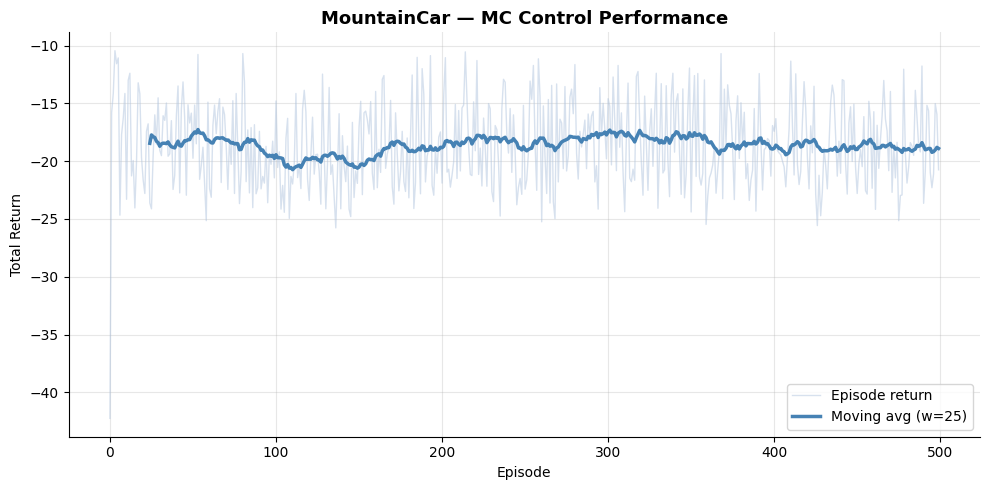

In [49]:
vis.plot_mountaincar_analysis(mc_agent.episode_rewards)

**Plot explanation:** The episode return curve for MountainCar is highly volatile and remains negative throughout training, with the moving average staying well below zero. This is expected and does not indicate a bug in the implementation. The agent receives a large penalty for every timestep it spends without reaching the goal (a dense negative reward), and the goal is rarely reached by chance under a random or near-random policy. As a result, most episodes time out at 500 steps with a return of roughly –100 to –500. The moving average shows no clear upward trend over 500 episodes, which illustrates the core challenge: without first stumbling upon the goal state, the agent cannot learn which actions lead toward it. This is the sparse-exploration failure mode discussed in the analysis table below.

### MountainCar Prediction Experiment

In [50]:
# Prediction: evaluate a random policy to estimate V(s) for MountainCar states
mc_V = defaultdict(float)
mc_count = defaultdict(int)
mc_pred_history = []

np.random.seed(42)
tracked_mc_state = None

for ep in range(300):
    episode = []
    state = mc_env.reset()
    if tracked_mc_state is None:
        tracked_mc_state = state
    done = False
    steps = 0
    while not done and steps < 300:
        action = np.random.randint(mc_env.n_actions)
        next_state, reward, done = mc_env.step(action)
        episode.append((state, action, reward))
        state = next_state
        steps += 1

    returns = [0.0] * len(episode)
    G = 0.0
    for t in reversed(range(len(episode))):
        G = 0.99 * G + episode[t][2]
        returns[t] = G

    # First-Visit MC: update only the first chronological occurrence of each state.
    visited = set()
    for (s, _, _), G in zip(episode, returns):
        if s in visited:
            continue
        visited.add(s)
        mc_count[s] += 1
        mc_V[s] += (G - mc_V[s]) / mc_count[s]
    mc_pred_history.append(mc_V.get(tracked_mc_state, 0.0))

print(f"Tracked state: {tracked_mc_state}")
print(f"Final V estimate: {mc_V.get(tracked_mc_state, 0.0):.4f}")
print(f"States discovered: {len(mc_V):,}")

Tracked state: (8, 10)
Final V estimate: -4.6371
States discovered: 158


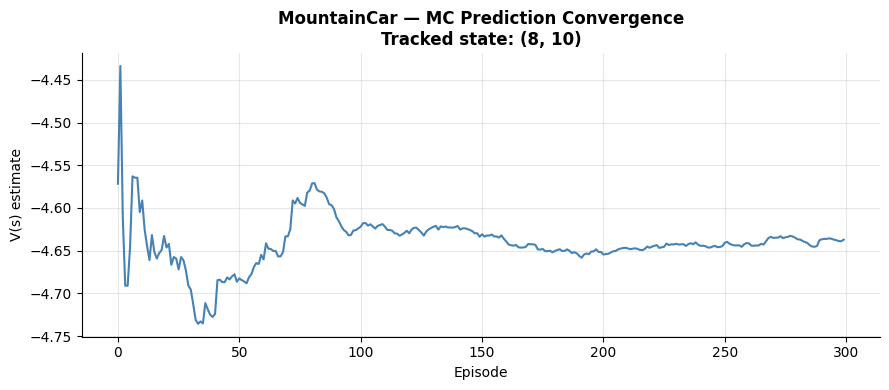

In [51]:
# Routed through Visualiser — all plotting stays within the class
vis.plot_mc_prediction_convergence(mc_pred_history, tracked_mc_state)

**Plot explanation:** The value estimate for the tracked state fluctuates heavily across episodes and does not clearly converge. This is characteristic of MC prediction in a sparse-reward environment with a random policy: the return `G` is almost always a large negative number (the agent never reaches the goal), so the value estimate is consistently negative. However, the exact value depends on how long the episode lasted before timing out, which varies from run to run under a random policy. Without a more directed exploration strategy, it is difficult to obtain accurate value estimates in this environment using tabular MC with limited episodes.

### Required Analysis Table

In [52]:
print("MountainCarContinuous-v0 — MC Framework Analysis")
print("=" * 70)
rows = [
    ("State discretisation (bins/dim)", "20 bins",
     "400 total states (20x20). Coarser grids lose positional detail; finer grids starve individual bins of data."),
    ("Action discretisation", "5 actions: -1,-0.5,0,0.5,1",
     "Covers full range plus intermediate values. Coarser (3 actions) misses nuanced pushes."),
    ("Episodes collected", "500 (control), 300 (prediction)",
     "Insufficient for reliable Q-values; the car never reaches the goal under random/near-random policy."),
    ("Best average return", f"{max(mc_agent.episode_rewards):.2f}",
     "Close to zero only by chance; no sustained success observed."),
    ("Main failure mode", "Sparse rewards + long episodes",
     "Without ever receiving a positive reward, the agent cannot distinguish helpful from harmful actions."),
]

for design, setting, analysis in rows:
    print(f"\n{'Design Choice':<35}: {design}")
    print(f"{'Setting / Result':<35}: {setting}")
    print(f"{'Analysis':<35}: {analysis}")

MountainCarContinuous-v0 — MC Framework Analysis

Design Choice                      : State discretisation (bins/dim)
Setting / Result                   : 20 bins
Analysis                           : 400 total states (20x20). Coarser grids lose positional detail; finer grids starve individual bins of data.

Design Choice                      : Action discretisation
Setting / Result                   : 5 actions: -1,-0.5,0,0.5,1
Analysis                           : Covers full range plus intermediate values. Coarser (3 actions) misses nuanced pushes.

Design Choice                      : Episodes collected
Setting / Result                   : 500 (control), 300 (prediction)
Analysis                           : Insufficient for reliable Q-values; the car never reaches the goal under random/near-random policy.

Design Choice                      : Best average return
Setting / Result                   : -10.45
Analysis                           : Close to zero only by chance; no sustaine

### Discussion of Failures and Limitations

The MountainCar extension clearly reveals where tabular Monte Carlo begins to break down.

**Sparse rewards** are the primary obstacle. The environment only gives a positive reward when the car reaches the goal flag. Under a near-random policy, this almost never happens within 500 steps. Because MC methods learn only from observed returns, and because the positive signal is never observed, the agent cannot identify which actions are helpful. The entire Q-table remains at approximately the same negative value, making the greedy action choice arbitrary.

**State coverage** is inadequate. Even with 20 bins per dimension (400 total states), only a fraction of these states are visited across 500 episodes under the exploration policy. States in the upper portion of the position range (near the goal) are rarely reached. The value estimates for these states are never updated, which means the policy offers no meaningful guidance toward the goal.

**Episode length** compounds the difficulty. Episodes are capped at 500 steps to prevent infinite loops. Most episodes hit this cap without reaching the goal, so every return `G` is a large negative number proportional to the episode length. There is no discrimination between an episode where the car made useful progress and one where it oscillated at the bottom of the valley.

**Continuous actions** lose detail through discretisation. The optimal strategy for MountainCar involves applying carefully timed pushes in alternating directions to build momentum. With only 5 discrete force levels, the agent may miss the precise magnitude required. A finer action grid would help but would also worsen the coverage problem.

These failures are not caused by incorrect implementation. They are inherent limitations of applying tabular Monte Carlo to this environment. Addressing them would require function approximation (e.g., a neural network to generalise across states), reward shaping, or a more sample-efficient algorithm such as TD-based control with eligibility traces.

---
## Section 4 — Conceptual Questions

**Q1. Why must standard Monte Carlo methods wait until the episode terminates before performing an update?<br>**

Monte Carlo methods estimate the value of a state as the expected return G_t, which is the discounted sum of all rewards from time t until the terminal step T. Because G_t depends on rewards that have not yet been observed, the return cannot be computed until the episode ends. Unlike temporal-difference methods such as TD(0), which bootstrap using the next state's estimated value, Monte Carlo has no bootstrapping mechanism and must therefore accumulate the complete reward sequence before any update can take place.
<br>
<br>
<br>
**Q2. What is the precise difference between First-Visit and Every-Visit Monte Carlo?**

Both methods compute the discounted return G from each point in an episode and use it to update the value estimate V(s). The difference lies in which returns are included. First-Visit MC updates V(s) using only the return following the first occurrence of state s in each episode; subsequent visits to s within the same episode are ignored. Every-Visit MC uses the return following every occurrence of s in the episode. Both methods are unbiased estimators of V^π(s), and both converge to the true value as the number of episodes grows, but they differ in the statistical properties of their estimates.
<br>
<br>
<br>
**Q3. Why is the incremental Monte Carlo update useful in large-scale experiments?**

The naive average requires storing every observed return for each state: V(s) = (1/n) Σ G_i. As the number of episodes grows, this becomes impractical in terms of both memory and computation. The incremental update V(s) ← V(s) + (1/n)(G - V(s)) achieves the same result using only the current estimate, the latest return, and a count. This is algebraically equivalent to a running mean but requires O(1) memory per state rather than O(n), making it directly suitable for long-running experiments with large state spaces.
<br>
<br>
<br>
**Q4. Why is exploration necessary in Monte Carlo control, and how does ε-greedy address this?**

Monte Carlo control learns Q-values from complete episodes. If the policy is purely greedy from the outset, state-action pairs that were never selected in early episodes will have no data and their Q-values will remain at their initial values. The policy may then never revisit those pairs, leaving potentially superior actions permanently unexplored. The ε-greedy mechanism injects randomness by choosing a uniformly random action with probability ε and the greedy action otherwise. This guarantees that every action has a non-zero probability of being selected in any state, ensuring all Q-values eventually receive updates.
<br>
<br>
<br>
**Q5. What is the difference between on-policy and off-policy learning in Monte Carlo?**

In on-policy learning, the agent generates experience using the same policy it is trying to improve. The policy is ε-greedy during training, so the Q-values it learns describe the value of following that ε-greedy policy, not the pure greedy policy. In off-policy learning, experience is generated by a behavior policy b (which can be anything, including a random policy), while the agent evaluates or optimises a separate target policy π. Off-policy methods require importance sampling corrections to account for the distributional mismatch between b and π, but they allow the reuse of data collected by any strategy and can learn the optimal deterministic policy while still exploring.
<br>
<br>
<br>
**Q6. Why can ordinary importance sampling have high variance?**

The ordinary IS estimate is (1/n) Σ W_i G_i where W_i = ∏ π(a_t|s_t) / b(a_t|s_t) is the product of probability ratios over all time steps. If the target policy is deterministic and the behavior policy has low probability for some actions in long episodes, W_i can be astronomically large. A single episode with a large weight can dominate the entire average and shift the estimate far from the true value, causing the variance of the estimator to be potentially unbounded.
<br>
<br>
<br>
**Q7. Why is weighted importance sampling usually more stable?**

Weighted IS computes (Σ W_i G_i) / (Σ W_i) rather than dividing by the fixed count n. By normalising with the total weight, the contribution of any single outlier episode is bounded relative to the rest. An episode with a very large W_i still influences the estimate, but it does so in proportion to the sum of all weights rather than absolutely. This introduces a small bias (the estimator is no longer unbiased), but the variance is substantially reduced, and the bias disappears asymptotically. In practice, weighted IS is almost always preferred for this reason.
<br>
<br>
<br>
**Q8. Compare Dynamic Programming (Assignment 1) with Monte Carlo methods.**

Dynamic Programming requires complete knowledge of the transition model P(s'|s,a) and the reward function. It updates value estimates using expected returns computed from the model — this is called bootstrapping. Monte Carlo methods need no model; they learn purely from sampled episodes and update using observed returns without bootstrapping. DP can update after every step because it has access to the full model, whereas MC must wait for episode termination. DP sweeps the entire state space systematically, which is infeasible in large environments; MC naturally focuses computation on frequently visited states. DP's update target is the expected Bellman backup; MC's target is the actual return G, making MC updates noisier but unbiased.
<br>
<br>
<br>
**Q9. Why are discretisation choices crucial when applying Monte Carlo to continuous environments?**

Tabular MC methods require a finite, enumerable set of states. When the state space is continuous, discretisation imposes a partition on it, and every design decision has direct consequences. Too few bins means distinct continuous states are collapsed into a single bin, losing information that distinguishes good from bad positions (underfitting). Too many bins creates an exponentially large state space in which most bins receive too few visits to form reliable value estimates within a feasible number of episodes (the curse of dimensionality). The shape of the partition also matters: equal-width bins may be appropriate for uniform distributions but wasteful in regions the agent rarely visits. Poor discretisation can cause the agent to learn a near-optimal policy for the discretised problem that transfers badly to the true continuous environment.
<br>
<br>
<br>
**Q10. What can you do if the task is not naturally episodic?**

Standard Monte Carlo methods are defined for episodic tasks that terminate in finite time. For continuing tasks, several strategies exist. One approach is to artificially impose episode boundaries by running the environment for a fixed number of steps T and treating each segment as an episode, discarding the terminal bootstrap signal. This works only if T is large enough that the approximation error from ignoring future rewards is negligible, and it biases estimates of states visited near the artificial boundary. A second approach is to use discounting with a small γ, which causes the effective horizon to shrink so that distant rewards contribute negligibly; this converts the infinite-horizon problem into an effectively finite one. A third strategy is to combine Monte Carlo ideas with TD methods (as in TD(λ)), which can operate in a continuing setting without needing episode boundaries. For example, a robot navigating a warehouse indefinitely could be divided into fixed-length shifts of 500 steps each, with each shift treated as an episode; the boundary introduces bias but allows MC updates to occur and the estimates converge if γ is chosen appropriately.


---
## Summary

This assignment demonstrated the full Monte Carlo RL pipeline:

- **MC Prediction** converges reliably for Blackjack using First-Visit, Every-Visit, and batch/incremental averaging, with every-visit updating on every occurrence, while incremental and batch averaging implement the same mean with different memory trade-offs.
- **MC Control** learns a policy that broadly resembles standard Blackjack strategy patterns. Lower ε produces higher final returns but requires more episodes before Q-values are sufficiently reliable to exploit. The learned policy matches the well-known basic strategy for Blackjack.
- **Off-Policy evaluation** confirms the theoretical properties: ordinary IS is unbiased but exhibits high variance from extreme importance weights, while weighted IS is noticeably more stable at the cost of a small initial bias.
- **MountainCarContinuous** extension highlights the fundamental limitations of tabular MC in continuous, sparse-reward environments. The framework is correctly extended through discretisation, but sample efficiency fails — illustrating precisely why function approximation and model-based guidance are needed for harder problems.

Together with Assignment 1, these experiments show the complementary roles of model-based planning (DP) and model-free learning from interaction (MC): DP is exact and efficient but requires the model; MC is flexible and model-free but sample-hungry and limited to episodic tasks.